Image shape: (1, 739, 415, 3)


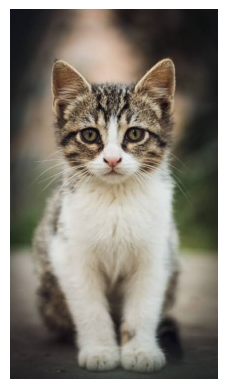

In [11]:
import tensorflow as tf
import matplotlib.pyplot as plt
import numpy as np

# Load your real image
img = tf.keras.utils.load_img(
    "C:\\Users\\yukine\\Downloads\\Machine_Learning_lab\\CNN_lab\\cat.jpg",
)
#image = tf.keras.utils.load_img("url_of_image",   target_size=(128,128))

# Convert image to a numerical array
img_array = tf.keras.utils.img_to_array(img)

# Add batch dimension: (height, width, channels) -> (1, height, width, channels)
img_array = tf.expand_dims(img_array, axis=0)

print("Image shape:", img_array.shape)

plt.imshow(img)
plt.axis("off")
plt.show()

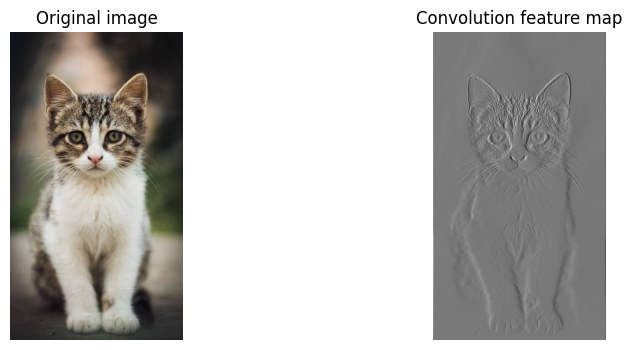

Feature map shape: (1, 739, 415, 1)


: 

In [ ]:
# One filter, 3x3 kernel, stride 1, zero padding
conv = tf.keras.layers.Conv2D(
    filters=1,
    kernel_size=3,
    strides=1,
    padding="same",
    use_bias=False
)

# Build the layer
conv.build(img_array.shape)

# Set a simple vertical edge-detection filter
edge_filter = np.array([
    [-1, 0, 1],
    [-1, 0, 1],
    [-1, 0, 1]
], dtype=np.float32)

# Apply the same filter to each RGB channel
kernel = np.zeros((3, 3, 3, 1), dtype=np.float32)
for channel in range(3):
    kernel[:, :, channel, 0] = edge_filter

conv.set_weights([kernel])

# Apply convolution
feature_map = conv(img_array)

plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.imshow(img)
plt.title("Original image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(feature_map[0, :, :, 0], cmap="gray")
plt.title("Convolution feature map")
plt.axis("off")

plt.show()

print("Feature map shape:", feature_map.shape)

In [ ]:
model = keras.models.Sequential([
keras.layers.Conv2D(64, 7, activation="relu", padding="same",
input_shape=[28, 28, 1]),
keras.layers.MaxPooling2D(2),
keras.layers.Conv2D(128, 3, activation="relu", padding="same"),
keras.layers.Conv2D(128, 3, activation="relu", padding="same"),
keras.layers.MaxPooling2D(2),
keras.layers.Conv2D(256, 3, activation="relu", padding="same"),
keras.layers.Conv2D(256, 3, activation="relu", padding="same"),
keras.layers.MaxPooling2D(2),
keras.layers.Flatten(),
keras.layers.Dense(128, activation="relu"),
keras.layers.Dropout(0.5),
keras.layers.Dense(64, activation="relu"),
keras.layers.Dropout(0.5),
keras.layers.Dense(10, activation="softmax")
])